# Pontualidade dos voos domésticos no Brasil em 2025

Base VRA da ANAC, só voos nacionais (tipo de linha N), janeiro a dezembro de 2025. O modelo estrela já está montado em `data/voos.duckdb` pelos scripts de `sql/`. Aqui as perguntas são respondidas em SQL direto no DuckDB; o pandas só entra pra teste estatístico e gráfico.

Pontualidade segue o padrão A15: voo realizado que chega até 15 minutos depois do horário previsto. Cancelado não entra na conta.

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

BANCO = Path("../data/voos.duckdb")
PASTA_FIG = Path("../reports/figuras")
PASTA_FIG.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(BANCO), read_only=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

## Visão geral

In [2]:
con.sql("""
    select
        count(*) as voos,
        sum(cancelado)::int as cancelados,
        round(100.0 * avg(cancelado), 2) as pct_cancelado,
        count(*) filter (where situacao = 'REALIZADO' and data_partida_prevista is null) as realizados_sem_previsto,
        count(pontual_15) as voos_na_a15,
        round(100.0 * avg(pontual_15), 1) as a15_pct
    from fato_voo
""").df()

,voos,cancelados,pct_cancelado,realizados_sem_previsto,voos_na_a15,a15_pct
0,804861,14067,1.75,15167,775627,85.8


804.861 voos nacionais previstos em 2025, dos quais 14.067 cancelados (1,75%). Outros 15.167 aparecem como realizados mas sem horário previsto (vinham como texto `null` no CSV), então não dá pra medir atraso deles e ficam fora da A15. Sobram 775.627 voos na conta, com A15 de 85,8%.

In [3]:
con.sql("""
    with chegadas as (
        select atraso_chegada_min as atraso, atraso_suspeito
        from fato_voo
        where atraso_chegada_min is not null
    )
    select
        round(avg(atraso), 2) as media_com_suspeitos,
        round(avg(atraso) filter (where atraso_suspeito = 0), 2) as media_sem_suspeitos,
        quantile_cont(atraso, 0.10) as p10,
        quantile_cont(atraso, 0.25) as p25,
        quantile_cont(atraso, 0.50) as mediana,
        quantile_cont(atraso, 0.75) as p75,
        quantile_cont(atraso, 0.90) as p90,
        quantile_cont(atraso, 0.99) as p99,
        max(atraso) as maximo,
        round(100.0 * avg(case when atraso > 60 then 1 else 0 end), 2) as pct_mais_de_1h
    from chegadas
""").df()

,media_com_suspeitos,media_sem_suspeitos,p10,p25,mediana,p75,p90,p99,maximo,pct_mais_de_1h
0,1.12,1.04,-18.0,-12.0,-5.0,6.0,23.0,112.0,44625,2.8


A mediana do atraso de chegada é -5 min: o voo típico chega 5 minutos antes do previsto, e metade dos voos fica entre -12 e +6 min. Mesmo assim a média dá +1,12 min. Quem puxa é a cauda direita: o p90 é 23 min, o p99 já é 112 min e 2,8% dos voos chegam com mais de uma hora de atraso. O máximo, 44.625 min (31 dias), é um dos 11 casos acima de 24h marcados como suspeitos. Só esses 11 voos mexem a média de 1,04 pra 1,12 min.

Por isso no resto do notebook uso A15 e percentis. Média de atraso aqui mais confunde do que ajuda.

## Por empresa

In [4]:
empresas = con.sql("""
    with por_empresa as (
        select
            e.nome as empresa,
            count(*) as voos,
            avg(f.cancelado) as taxa_cancelado,
            count(f.pontual_15) as n,
            sum(f.pontual_15) as pontuais,
            avg(f.atraso_chegada_min) filter (where f.pontual_15 = 0 and f.atraso_suspeito = 0) as atraso_medio_atrasados
        from fato_voo f
        join dim_empresa e on e.icao = f.empresa_icao
        group by e.nome
        having count(*) > 1000
    ),
    proporcoes as (
        select *, pontuais / n as p, 1.96 as z
        from por_empresa
    )
    select
        empresa,
        voos,
        round(100 * taxa_cancelado, 2) as pct_cancelado,
        round(100 * p, 2) as a15_pct,
        -- intervalo de wilson, melhor que o normal pras empresas pequenas
        round(100 * (p + z * z / (2 * n) - z * sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / (1 + z * z / n), 2) as ic95_inf,
        round(100 * (p + z * z / (2 * n) + z * sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / (1 + z * z / n), 2) as ic95_sup,
        round(atraso_medio_atrasados, 1) as atraso_medio_atrasados_min
    from proporcoes
    order by voos desc
""").df()
empresas

,empresa,voos,pct_cancelado,a15_pct,ic95_inf,ic95_sup,atraso_medio_atrasados_min
0,Azul,288757,1.42,86.02,85.89,86.15,53.2
1,LATAM,267242,1.68,83.78,83.63,83.92,39.0
2,Gol,222852,1.05,88.51,88.38,88.64,51.3
3,Azul Conecta,17852,12.23,80.84,80.18,81.48,64.4
4,SID,2894,10.06,74.83,73.07,76.50,43.9
5,VoePass,2237,11.89,67.90,65.76,69.97,91.9
6,Abaeté,1467,12.75,96.92,95.73,97.79,65.4


Entre as sete empresas com mais de 1.000 voos, a Gol tem a melhor A15 entre as grandes (88,51%, IC de 88,38% a 88,64%), seguida de Azul (86,02%) e LATAM (83,78%). Com mais de 200 mil voos cada, os intervalos têm menos de 0,3 ponto de largura e não se encostam.

Duas coisas que a A15 sozinha esconde:
- A Abaeté tem 96,92% de A15, mas cancela 12,75% dos voos. Azul Conecta (12,23%) e VoePass (11,89%) também cancelam perto de 12%, contra 1,05% a 1,68% das três grandes. Pontualidade sem cancelamento do lado engana.
- A LATAM atrasa mais vezes, só que quando atrasa o atraso médio é 39,0 min, contra 53,2 da Azul e 51,3 da Gol. A VoePass é o pior caso nas duas pontas: 67,90% de A15 e 91,9 min de atraso médio entre os atrasados.

O intervalo da Abaeté (95,73% a 97,79%) é bem mais largo que o das grandes porque são só 1.467 voos. É pra isso que serve o Wilson: com amostra pequena e proporção perto de 100%, o intervalo normal fica ruim.

In [5]:
grandes = con.sql("""
    select
        e.nome as empresa,
        sum(f.pontual_15) as pontuais,
        count(f.pontual_15) - sum(f.pontual_15) as atrasados
    from fato_voo f
    join dim_empresa e on e.icao = f.empresa_icao
    where f.empresa_icao in ('AZU', 'TAM', 'GLO')
    group by e.nome
    order by e.nome
""").df().set_index("empresa")

tabela = grandes[["pontuais", "atrasados"]].to_numpy(dtype=float)
chi2, p_valor, gl, _ = stats.chi2_contingency(tabela)
cramer_v = np.sqrt(chi2 / (tabela.sum() * (min(tabela.shape) - 1)))
print(f"qui-quadrado = {chi2:.1f}, gl = {gl}, p = {p_valor:.2e}, V de Cramér = {cramer_v:.3f}")

qui-quadrado = 2193.7, gl = 2, p = 0.00e+00, V de Cramér = 0.054


In [6]:
n = grandes["pontuais"] + grandes["atrasados"]
p = grandes["pontuais"] / n

pares = []
for a, b in [("Gol", "Azul"), ("Gol", "LATAM"), ("Azul", "LATAM")]:
    dif = p[a] - p[b]
    ep = np.sqrt(p[a] * (1 - p[a]) / n[a] + p[b] * (1 - p[b]) / n[b])
    pares.append({"comparacao": f"{a} - {b}", "dif_pp": 100 * dif,
                  "ic95_inf_pp": 100 * (dif - 1.96 * ep), "ic95_sup_pp": 100 * (dif + 1.96 * ep)})
pd.DataFrame(pares).round(2)

,comparacao,dif_pp,ic95_inf_pp,ic95_sup_pp
0,Gol - Azul,2.49,2.31,2.68
1,Gol - LATAM,4.73,4.54,4.93
2,Azul - LATAM,2.24,2.05,2.43


O qui-quadrado entre Azul, Gol e LATAM dá 2.193,7 com 2 graus de liberdade e p-valor que o float nem consegue representar (sai 0). Com 755.041 voos na conta isso era esperado: qualquer diferença vira "significativa". A pergunta útil é se a diferença é grande.

O V de Cramér é 0,054, ou seja, a empresa explica pouco da pontualidade de um voo individual. Em pontos percentuais, a Gol fica 4,73 pp acima da LATAM (IC de 4,54 a 4,93) e 2,49 pp acima da Azul; a Azul fica 2,24 pp acima da LATAM. Quase 5 voos a mais no horário a cada 100 é diferença que o passageiro sente, então eu reportaria a diferença em pp com intervalo, e não o p-valor.

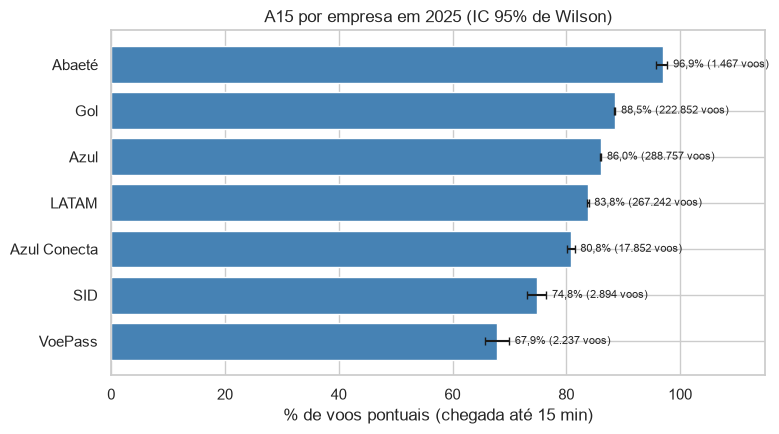

In [7]:
plot_emp = empresas.sort_values("a15_pct")
erro = [plot_emp["a15_pct"] - plot_emp["ic95_inf"], plot_emp["ic95_sup"] - plot_emp["a15_pct"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_emp["empresa"], plot_emp["a15_pct"], xerr=erro, color="steelblue", capsize=3)
for i, (a15, sup, voos) in enumerate(zip(plot_emp["a15_pct"], plot_emp["ic95_sup"], plot_emp["voos"])):
    rotulo = f"{a15:.1f}%".replace(".", ",") + f" ({voos:,} voos)".replace(",", ".")
    ax.text(sup + 1, i, rotulo, va="center", fontsize=8)
ax.set_xlim(0, 115)
ax.set_title("A15 por empresa em 2025 (IC 95% de Wilson)")
ax.set_xlabel("% de voos pontuais (chegada até 15 min)")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(PASTA_FIG / "01_a15_por_empresa.png", dpi=120)
plt.show()

## Hora do dia

In [8]:
por_hora = con.sql("""
    select
        hora_partida_prevista as hora,
        count(*) as voos,
        round(100.0 * avg(pontual_15), 1) as a15_pct,
        round(avg(atraso_partida_min) filter (where atraso_suspeito = 0), 1) as atraso_medio_partida_min
    from fato_voo
    where hora_partida_prevista is not null
    group by hora
    order by hora
""").df()
por_hora

,hora,voos,a15_pct,atraso_medio_partida_min
0,0,3224,87.1,11.1
1,1,3309,88.9,1.3
2,2,14228,89.4,1.3
3,3,16233,91.3,-0.3
4,4,12971,93.2,-1.5
5,5,26144,93.8,-2.7
6,6,38573,93.4,-1.2
7,7,32164,88.8,3.5
8,8,55162,88.6,4.0
9,9,47525,88.6,3.6


A A15 é máxima na primeira onda da manhã: 93,8% às 5h e 93,4% às 6h. Daí cai quase sem parar até 80,9% às 19h, uma diferença de 12,9 pontos. O atraso médio de partida conta a mesma história: -2,7 min às 5h (sai adiantado), 4,0 min às 8h, 7,5 min às 17h. Às 21h tem um respiro (85,7%) e às 22h volta a 81,2%.

É o padrão do efeito cascata: o avião que atrasa de manhã leva o atraso pros voos seguintes. A base não tem matrícula da aeronave, então não consigo seguir o mesmo avião ao longo do dia. O número é compatível com a cascata, mas não prova sozinho.

In [9]:
con.sql("""
    with faixas as (
        select
            e.nome as empresa,
            case
                when hora_partida_prevista between 5 and 6 then '1 primeira onda (5h-6h)'
                when hora_partida_prevista between 7 and 11 then '2 manhã (7h-11h)'
                when hora_partida_prevista between 12 and 16 then '3 tarde (12h-16h)'
                when hora_partida_prevista between 17 and 20 then '4 fim de tarde (17h-20h)'
            end as faixa,
            pontual_15
        from fato_voo f
        join dim_empresa e on e.icao = f.empresa_icao
        where f.empresa_icao in ('AZU', 'TAM', 'GLO')
    )
    pivot (select * from faixas where faixa is not null)
    on empresa
    using round(100.0 * avg(pontual_15), 1)
    order by faixa
""").df()

,faixa,Azul,Gol,LATAM
0,1 primeira onda (5h-6h),93.4,93.9,94.0
1,2 manhã (7h-11h),88.3,89.6,87.4
2,3 tarde (12h-16h),83.7,87.6,82.7
3,4 fim de tarde (17h-20h),81.7,85.8,77.8


O padrão vale pras três grandes. Na primeira onda elas praticamente empatam (93,4% a 94,0%). A diferença aparece depois: da primeira onda ao fim da tarde a LATAM perde 16,2 pontos (94,0% para 77,8%), a Azul 11,7 e a Gol 8,1. A vantagem da Gol no ano vem quase toda da tarde e do começo da noite.

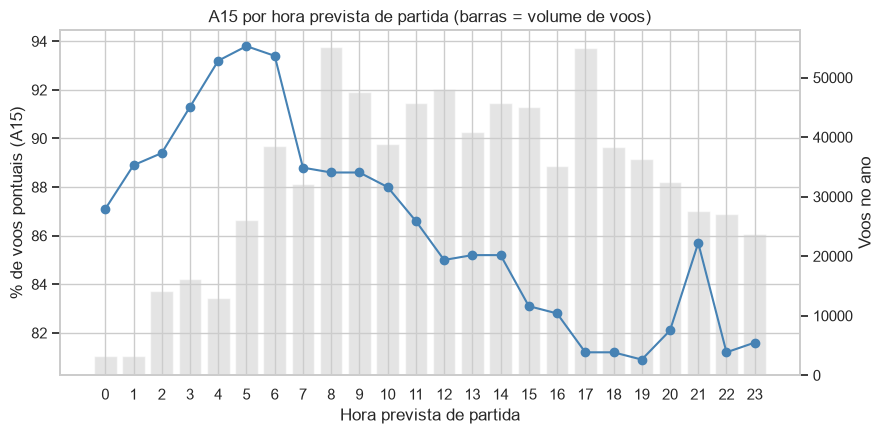

In [10]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(por_hora["hora"], por_hora["a15_pct"], marker="o", color="steelblue", label="A15 (%)")
ax1.set_ylabel("% de voos pontuais (A15)")
ax1.set_xlabel("Hora prevista de partida")
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.bar(por_hora["hora"], por_hora["voos"], color="lightgray", alpha=0.6)
ax2.set_ylabel("Voos no ano")
ax2.grid(False)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

ax1.set_title("A15 por hora prevista de partida (barras = volume de voos)")
plt.tight_layout()
fig.savefig(PASTA_FIG / "02_a15_por_hora.png", dpi=120)
plt.show()

## Sazonalidade

In [11]:
por_mes = con.sql("""
    with mensal as (
        select
            d.mes,
            d.nome_mes,
            count(*) as voos,
            avg(f.pontual_15) as a15,
            avg(f.cancelado) as taxa_cancelado
        from fato_voo f
        join dim_data d on d.data = f.data_partida_prevista
        group by d.mes, d.nome_mes
    )
    select
        mes,
        nome_mes,
        voos,
        round(100 * a15, 1) as a15_pct,
        round(100 * (a15 - lag(a15) over (order by mes)), 1) as var_a15_pp,
        round(100 * taxa_cancelado, 2) as pct_cancelado
    from mensal
    order by mes
""").df()
por_mes

,mes,nome_mes,voos,a15_pct,var_a15_pp,pct_cancelado
0,1,Janeiro,69708,85.2,NaN,2.60
1,2,Fevereiro,61166,83.4,-1.8,2.63
2,3,Março,64248,88.8,5.4,1.39
3,4,Abril,63944,85.9,-2.8,1.85
4,5,Maio,65861,88.5,2.5,1.16
5,6,Junho,64477,86.8,-1.7,1.60
6,7,Julho,68473,87.5,0.7,1.70
7,8,Agosto,66576,89.6,2.1,1.24
8,9,Setembro,65344,88.6,-1.0,1.57
9,10,Outubro,67619,85.9,-2.7,1.44


De janeiro a novembro a A15 fica entre 83,4% (fevereiro) e 89,6% (agosto). Dezembro despenca pra 74,2%, 11,1 pontos abaixo de novembro, e tem o maior cancelamento do ano (2,87%). Janeiro e fevereiro também cancelam mais que a média (2,60% e 2,63%).

O join com `dim_data` deixa de fora 1 voo previsto pra 01/01/2026 que veio no arquivo de dezembro, por isso janeiro aparece com 69.708 voos e não 69.709.

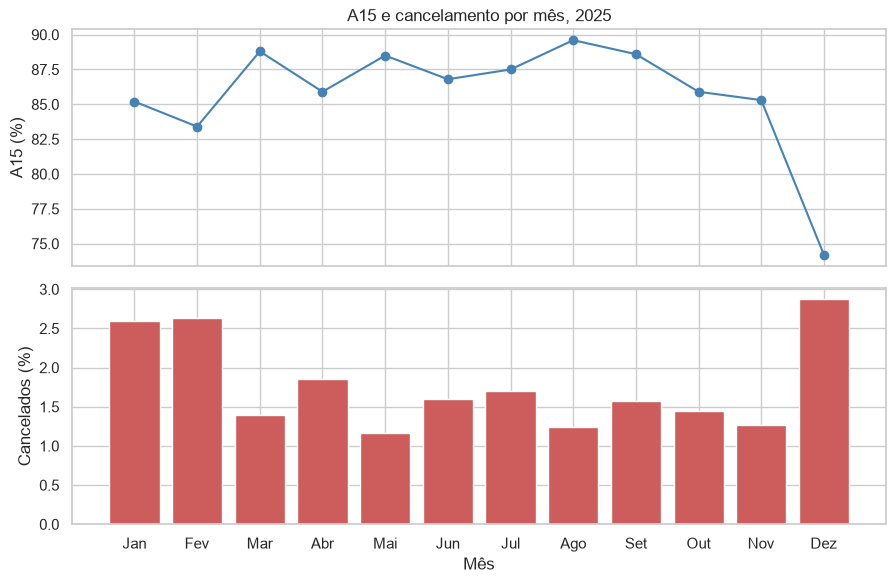

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
rotulos = por_mes["nome_mes"].str[:3]
axes[0].plot(rotulos, por_mes["a15_pct"], marker="o", color="steelblue")
axes[0].set_ylabel("A15 (%)")
axes[0].set_title("A15 e cancelamento por mês, 2025")
axes[1].bar(rotulos, por_mes["pct_cancelado"], color="indianred")
axes[1].set_ylabel("Cancelados (%)")
axes[1].set_xlabel("Mês")
plt.tight_layout()
fig.savefig(PASTA_FIG / "03_a15_cancelamento_por_mes.png", dpi=120)
plt.show()

In [13]:
con.sql("""
    with por_dia as (
        select
            data_partida_prevista as data,
            count(*) as voos,
            avg(pontual_15) as a15,
            avg(cancelado) as taxa_cancelado
        from fato_voo
        where year(data_partida_prevista) = 2025
        group by data
    )
    select
        data,
        voos,
        round(100 * a15, 1) as a15_pct,
        round(100 * taxa_cancelado, 1) as pct_cancelado
    from por_dia
    qualify rank() over (order by a15) <= 10
    order by a15
""").df()

,data,voos,a15_pct,pct_cancelado
0,2025-12-11,2310,35.2,14.4
1,2025-12-10,2304,35.6,19.7
2,2025-09-22,2266,48.1,8.1
3,2025-12-12,2313,53.5,3.5
4,2025-12-09,2316,54.5,5.5
5,2025-12-13,2070,59.3,2.9
6,2025-10-29,2208,65.3,4.5
7,2025-12-16,2318,65.3,2.5
8,2025-12-08,2350,66.3,4.2
9,2025-07-28,2290,66.5,3.5


Sete dos dez piores dias do ano são de dezembro. Em 10 e 11/12 a A15 ficou em 35,6% e 35,2%, e no dia 10 um em cada cinco voos foi cancelado (19,7%). Fora de dezembro, os piores dias foram 22/09 (48,1%, com 8,1% cancelados), 29/10 e 28/07. Vale ver onde 10 e 11/12 se concentraram:

In [14]:
con.sql("""
    select
        f.origem_icao,
        a.municipio,
        count(*) as voos,
        sum(f.cancelado)::int as cancelados,
        round(100.0 * avg(f.pontual_15), 1) as a15_pct,
        round(100.0 * sum(f.cancelado) / sum(sum(f.cancelado)) over (), 1) as pct_dos_cancelamentos
    from fato_voo f
    left join dim_aeroporto a on a.icao = f.origem_icao
    where f.data_partida_prevista between date '2025-12-10' and date '2025-12-11'
    group by f.origem_icao, a.municipio
    qualify row_number() over (order by sum(f.cancelado) desc, f.origem_icao) <= 8
    order by cancelados desc, f.origem_icao
""").df()

,origem_icao,municipio,voos,cancelados,a15_pct,pct_dos_cancelamentos
0,SBSP,SÃO PAULO,581,174,22.1,22.2
1,SBGR,GUARULHOS,566,91,19.8,11.6
2,SBRJ,RIO DE JANEIRO,176,63,21.2,8.0
3,SBBR,BRASÍLIA,348,37,38.3,4.7
4,SBCF,CONFINS,308,36,41.2,4.6
5,SBPA,PORTO ALEGRE,169,36,29.3,4.6
6,SBCT,CURITIBA,157,34,30.9,4.3
7,SBKP,CAMPINAS,301,30,24.7,3.8


Congonhas sozinho teve 174 cancelamentos nos dois dias (22,2% de todos os cancelamentos do período), Guarulhos 91 e Santos Dumont 63. Em Congonhas, Guarulhos, Santos Dumont e Campinas a A15 de quem conseguiu voar ficou entre 19,8% e 24,7%. Foi um evento concentrado no eixo São Paulo que espalhou atraso pro resto da malha. A base não traz a causa (tempo, pane, greve), então não vou chutar.

In [15]:
con.sql("""
    select
        round(100.0 * avg(pontual_15) filter (where month(data_partida_prevista) = 12), 1) as a15_dezembro,
        round(100.0 * avg(pontual_15) filter (where data_partida_prevista not between date '2025-12-08' and date '2025-12-17'
                                                and month(data_partida_prevista) = 12), 1) as a15_dez_sem_8_a_17,
        round(100.0 * avg(pontual_15) filter (where month(data_partida_prevista) < 12), 1) as a15_jan_a_nov
    from fato_voo
""").df()

,a15_dezembro,a15_dez_sem_8_a_17,a15_jan_a_nov
0,74.2,81.2,86.9


Tirando o período de 8 a 17/12 (22.761 voos), dezembro sobe de 74,2% pra 81,2%. Ainda fica abaixo dos 86,9% de janeiro a novembro, então o fim de ano tem um efeito próprio, mas a maior parte da queda vem desses dez dias. No gráfico mensal isso some; na série diária fica óbvio:

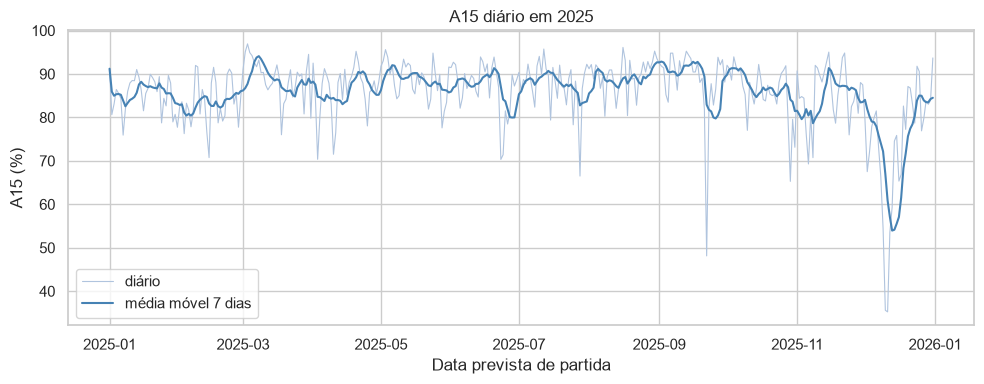

In [16]:
diario = con.sql("""
    select
        data_partida_prevista as data,
        avg(pontual_15) as a15,
        -- média móvel de 7 dias pra tirar o ruído do dia da semana
        avg(avg(pontual_15)) over (order by data_partida_prevista rows between 6 preceding and current row) as a15_mm7
    from fato_voo
    where year(data_partida_prevista) = 2025
    group by data_partida_prevista
    order by data
""").df()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(diario["data"], 100 * diario["a15"], color="lightsteelblue", linewidth=0.8, label="diário")
ax.plot(diario["data"], 100 * diario["a15_mm7"], color="steelblue", label="média móvel 7 dias")
ax.set_title("A15 diário em 2025")
ax.set_xlabel("Data prevista de partida")
ax.set_ylabel("A15 (%)")
ax.legend(loc="lower left")
plt.tight_layout()
fig.savefig(PASTA_FIG / "05_a15_diario.png", dpi=120)
plt.show()

In [17]:
con.sql("""
    select
        d.dia_semana,
        d.nome_dia,
        count(*) as voos,
        round(100.0 * avg(f.pontual_15), 1) as a15_pct,
        round(100.0 * avg(f.cancelado), 2) as pct_cancelado
    from fato_voo f
    join dim_data d on d.data = f.data_partida_prevista
    group by d.dia_semana, d.nome_dia
    order by d.dia_semana
""").df()

,dia_semana,nome_dia,voos,a15_pct,pct_cancelado
0,0,Domingo,107358,88.7,1.24
1,1,Segunda,117549,85.6,1.87
2,2,Terça,116415,85.1,2.09
3,3,Quarta,117696,85.1,2.16
4,4,Quinta,115691,84.1,1.99
5,5,Sexta,116463,83.5,1.78
6,6,Sábado,98521,89.1,1.21


Sábado (89,1%) e domingo (88,7%) são os dias mais pontuais e os que menos cancelam (1,21% e 1,24%). Nos dias úteis a A15 vai de 85,6% na segunda a 83,5% na sexta, e o cancelamento chega a 2,16% na quarta. O fim de semana também tem menos voos (98.521 aos sábados contra uns 117 mil nos dias úteis), com a malha mais folgada.

## Aeroportos

In [18]:
aeroportos = con.sql("""
    with partidas as (
        select
            origem_icao as icao,
            count(*) as partidas,
            avg(case when atraso_partida_min <= 15 then 1.0 when atraso_partida_min > 15 then 0.0 end) as a15_partida,
            avg(cancelado) as taxa_cancelado
        from fato_voo
        group by origem_icao
    ),
    chegadas as (
        select destino_icao as icao, avg(pontual_15) as a15_chegada
        from fato_voo
        group by destino_icao
    )
    select
        p.icao,
        a.municipio,
        a.uf,
        p.partidas,
        round(100 * p.a15_partida, 1) as a15_partida_pct,
        round(100 * c.a15_chegada, 1) as a15_chegada_pct,
        round(100 * p.taxa_cancelado, 2) as pct_cancelado
    from partidas p
    join chegadas c on c.icao = p.icao
    left join dim_aeroporto a on a.icao = p.icao
    qualify row_number() over (order by p.partidas desc) <= 15
    order by p.partidas desc
""").df()
aeroportos

,icao,municipio,uf,partidas,a15_partida_pct,a15_chegada_pct,pct_cancelado
0,SBGR,GUARULHOS,SP,98965,75.4,82.9,1.42
1,SBSP,SÃO PAULO,SP,95003,83.2,88.2,1.72
2,SBCF,CONFINS,MG,57094,84.3,84.6,1.56
3,SBBR,BRASÍLIA,DF,55491,89.1,88.0,0.96
4,SBKP,CAMPINAS,SP,55319,84.9,85.6,1.79
5,SBGL,RIO DE JANEIRO,RJ,42462,87.1,88.2,0.95
6,SBRF,RECIFE,PE,35539,87.2,86.8,1.30
7,SBRJ,RIO DE JANEIRO,RJ,29367,90.1,89.0,2.74
8,SBSV,SALVADOR,BA,27161,88.8,87.0,1.39
9,SBPA,PORTO ALEGRE,RS,26745,86.6,84.8,1.91


Guarulhos tem mais partidas (98.965) e a pior A15 de partida do grupo, 75,4%. Na chegada o mesmo aeroporto fica em 82,9%, uma diferença de 7,5 pontos: muita coisa sai atrasada de lá. Congonhas vem logo atrás em volume (95.003) com 83,2% na partida e 88,2% na chegada.

Santos Dumont tem a melhor partida do top 15 (90,1%), mas o maior cancelamento (2,74%). Curitiba (2,39%) e Porto Alegre (1,91%) também cancelam acima da média.

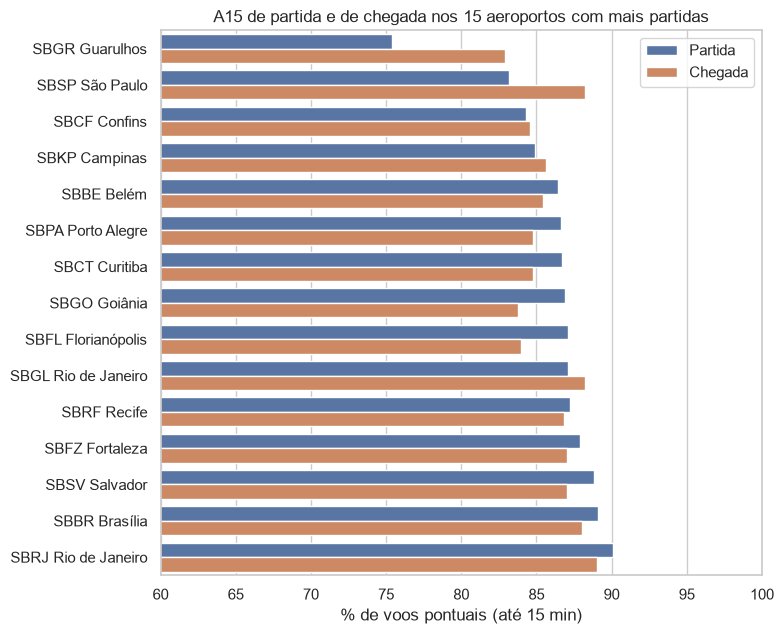

In [19]:
aeroportos["aeroporto"] = aeroportos["icao"] + " " + aeroportos["municipio"].str.title().str.replace(" De ", " de ")
ordem = aeroportos.sort_values("a15_partida_pct")["aeroporto"]

plot_aero = aeroportos.melt(id_vars="aeroporto", value_vars=["a15_partida_pct", "a15_chegada_pct"],
                            var_name="medida", value_name="a15")
plot_aero["medida"] = plot_aero["medida"].map({"a15_partida_pct": "Partida", "a15_chegada_pct": "Chegada"})

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.barplot(data=plot_aero, y="aeroporto", x="a15", hue="medida", order=ordem, ax=ax)
ax.set_xlim(60, 100)
ax.set_title("A15 de partida e de chegada nos 15 aeroportos com mais partidas")
ax.set_xlabel("% de voos pontuais (até 15 min)")
ax.set_ylabel("")
ax.legend(title="")
plt.tight_layout()
fig.savefig(PASTA_FIG / "04_a15_aeroportos.png", dpi=120)
plt.show()

In [20]:
con.sql("""
    with por_aeroporto as (
        select
            f.origem_icao as icao,
            a.municipio,
            count(*) as partidas,
            avg(case when f.atraso_partida_min <= 15 then 1.0 when f.atraso_partida_min > 15 then 0.0 end) as a15_partida
        from fato_voo f
        left join dim_aeroporto a on a.icao = f.origem_icao
        group by f.origem_icao, a.municipio
        having count(*) >= 5000
    ),
    ranqueado as (
        select
            *,
            rank() over (order by a15_partida) as pos_pior,
            rank() over (order by a15_partida desc) as pos_melhor
        from por_aeroporto
    )
    select
        case when pos_pior <= 5 then 'pior' else 'melhor' end as grupo,
        icao,
        municipio,
        partidas,
        round(100 * a15_partida, 1) as a15_partida_pct
    from ranqueado
    where pos_pior <= 5 or pos_melhor <= 5
    order by a15_partida
""").df()

,grupo,icao,municipio,partidas,a15_partida_pct
0,pior,SBGR,GUARULHOS,98965,75.4
1,pior,SBFI,FOZ DO IGUAÇU,7341,82.8
2,pior,SBSP,SÃO PAULO,95003,83.2
3,pior,SBCF,CONFINS,57094,84.3
4,pior,SBUL,UBERLÂNDIA,5242,84.5
5,melhor,SBCG,CAMPO GRANDE,5430,88.4
6,melhor,SBSV,SALVADOR,27161,88.8
7,melhor,SBBR,BRASÍLIA,55491,89.1
8,melhor,SBMO,MACEIÓ,9736,89.2
9,melhor,SBRJ,RIO DE JANEIRO,29367,90.1


Entre os aeroportos com pelo menos 5.000 partidas, Guarulhos é ponto fora da curva. O segundo pior, Foz do Iguaçu, já tem 82,8%, e do segundo pior ao melhor (Santos Dumont, 90,1%) são só 7,3 pontos. Do lado bom aparecem Maceió (89,2%), Brasília (89,1%), Salvador (88,8%) e Campo Grande (88,4%).

In [21]:
con.sql("""
    select
        coalesce(a.regiao, 'sem cadastro') as regiao_origem,
        count(*) as voos,
        round(100.0 * count(*) / sum(count(*)) over (), 1) as pct_dos_voos,
        round(100.0 * avg(case when f.atraso_partida_min <= 15 then 1.0 when f.atraso_partida_min > 15 then 0.0 end), 1) as a15_partida_pct,
        round(100.0 * avg(f.pontual_15), 1) as a15_chegada_pct,
        round(100.0 * avg(f.cancelado), 2) as pct_cancelado
    from fato_voo f
    left join dim_aeroporto a on a.icao = f.origem_icao
    group by coalesce(a.regiao, 'sem cadastro')
    order by voos desc
""").df()

,regiao_origem,voos,pct_dos_voos,a15_partida_pct,a15_chegada_pct,pct_cancelado
0,Sudeste,420510,52.2,82.9,84.3,1.76
1,Nordeste,144688,18.0,87.7,87.5,1.40
2,Sul,101967,12.7,86.6,86.1,2.30
3,Centro-Oeste,88723,11.0,88.4,88.8,1.16
4,Norte,47392,5.9,87.0,87.3,2.31
5,sem cadastro,1581,0.2,86.0,87.7,10.06


O Sudeste concentra 52,2% dos voos e tem a pior pontualidade (82,9% na partida, 84,3% na chegada), puxado por Guarulhos e Congonhas. O Centro-Oeste é o melhor (88,4% e 88,8%). Norte (2,31%) e Sul (2,30%) cancelam mais. Os 1.581 voos que saem dos 11 aeroportos sem cadastro cancelam 10,06%; são aeródromos pequenos.

## Rotas

In [22]:
con.sql("""
    with rotas as (
        select
            origem_icao,
            destino_icao,
            count(*) as voos,
            avg(pontual_15) as a15,
            avg(cancelado) as taxa_cancelado
        from fato_voo
        group by origem_icao, destino_icao
    )
    select
        rank() over (order by r.voos desc) as posicao,
        r.origem_icao || '-' || r.destino_icao as rota,
        o.municipio || ' > ' || d.municipio as cidades,
        r.voos,
        round(100.0 * r.voos / sum(r.voos) over (), 2) as pct_dos_voos,
        round(100 * r.a15, 1) as a15_pct,
        round(100 * r.taxa_cancelado, 2) as pct_cancelado
    from rotas r
    left join dim_aeroporto o on o.icao = r.origem_icao
    left join dim_aeroporto d on d.icao = r.destino_icao
    qualify posicao <= 10
    order by posicao
""").df()

,posicao,rota,cidades,voos,pct_dos_voos,a15_pct,pct_cancelado
0,1,SBRJ-SBSP,RIO DE JANEIRO > SÃO PAULO,18824,2.34,90.1,3.51
1,2,SBSP-SBRJ,SÃO PAULO > RIO DE JANEIRO,18799,2.34,88.4,3.35
2,3,SBBR-SBSP,BRASÍLIA > SÃO PAULO,8990,1.12,88.8,1.42
3,4,SBSP-SBBR,SÃO PAULO > BRASÍLIA,8976,1.12,83.5,0.74
4,5,SBCF-SBSP,CONFINS > SÃO PAULO,8327,1.03,84.9,1.98
5,6,SBSP-SBCF,SÃO PAULO > CONFINS,8305,1.03,84.3,1.67
6,7,SBPA-SBSP,PORTO ALEGRE > SÃO PAULO,8090,1.01,88.7,2.53
7,8,SBSP-SBPA,SÃO PAULO > PORTO ALEGRE,8081,1.00,86.1,1.91
8,9,SBCT-SBSP,CURITIBA > SÃO PAULO,7163,0.89,87.2,2.40
9,10,SBSP-SBCT,SÃO PAULO > CURITIBA,7133,0.89,86.4,2.06


A ponte aérea Santos Dumont-Congonhas lidera nos dois sentidos (18.824 e 18.799 voos, 2,34% do total cada). As dez maiores rotas passam todas por Congonhas. A ponte é pontual (90,1% e 88,4%), mas cancela 3,51% e 3,35%, o dobro da média geral.

Nos cinco pares, o sentido que sai de Congonhas é sempre menos pontual que a volta. O caso mais forte é Brasília: 88,8% chegando em Congonhas e 83,5% saindo de lá.

In [23]:
con.sql("""
    with rota_empresa as (
        select origem_icao, destino_icao, empresa_icao, count(*) as voos
        from fato_voo
        group by origem_icao, destino_icao, empresa_icao
    ),
    principal as (
        -- empresa com mais voos na rota e a fatia dela
        select
            origem_icao,
            destino_icao,
            empresa_icao,
            voos / sum(voos) over (partition by origem_icao, destino_icao) as fatia
        from rota_empresa
        qualify row_number() over (partition by origem_icao, destino_icao order by voos desc) = 1
    ),
    rotas as (
        select
            origem_icao,
            destino_icao,
            count(*) as voos,
            avg(pontual_15) as a15
        from fato_voo
        group by origem_icao, destino_icao
        having count(*) >= 1000
    )
    select
        rank() over (order by r.a15) as pos_pior,
        r.origem_icao || '-' || r.destino_icao as rota,
        o.municipio || ' > ' || d.municipio as cidades,
        r.voos,
        round(100 * r.a15, 1) as a15_pct,
        e.nome as empresa_principal,
        round(100 * p.fatia, 0) as fatia_pct
    from rotas r
    join principal p using (origem_icao, destino_icao)
    left join dim_empresa e on e.icao = p.empresa_icao
    left join dim_aeroporto o on o.icao = r.origem_icao
    left join dim_aeroporto d on d.icao = r.destino_icao
    qualify pos_pior <= 10
    order by pos_pior
""").df()

,pos_pior,rota,cidades,voos,a15_pct,empresa_principal,fatia_pct
0,1,SBGR-SBSL,GUARULHOS > SÃO LUÍS,1677,72.5,LATAM,81.0
1,2,SBGR-SBLO,GUARULHOS > LONDRINA,1071,72.6,LATAM,100.0
2,3,SBGR-SBGO,GUARULHOS > GOIÂNIA,2829,75.2,LATAM,62.0
3,4,SBSP-SBCY,SÃO PAULO > CUIABÁ,1027,75.4,LATAM,69.0
4,5,SBGR-SBSV,GUARULHOS > SALVADOR,4037,75.7,LATAM,62.0
5,6,SBCF-SBJR,CONFINS > RIO DE JANEIRO,1260,75.7,Azul Conecta,100.0
6,7,SBGR-SBVC,GUARULHOS > VITÓRIA DA CONQUISTA,1054,75.9,LATAM,64.0
7,8,SBJR-SBCF,RIO DE JANEIRO > CONFINS,1268,76.1,Azul Conecta,100.0
8,9,SBGR-SBFZ,GUARULHOS > FORTALEZA,3874,76.3,LATAM,68.0
9,10,SBGR-SBVT,GUARULHOS > VITÓRIA,3068,76.4,LATAM,70.0


In [24]:
con.sql("""
    select count(*) as rotas_com_1000_voos
    from (
        select origem_icao, destino_icao
        from fato_voo
        group by origem_icao, destino_icao
        having count(*) >= 1000
    )
""").df()

,rotas_com_1000_voos
0,232


São 232 rotas com pelo menos 1.000 voos no ano. Das dez piores, sete saem de Guarulhos e uma de Congonhas, e a LATAM é a empresa principal em oito delas (de 62% a 100% dos voos da rota). A pior é Guarulhos-São Luís, com 72,5%. As outras duas são Confins-Jacarepaguá nos dois sentidos, operadas só pela Azul Conecta (75,7% e 76,1%).

Isso levanta uma dúvida sobre o ranking de empresas: a LATAM tem hub em Guarulhos. Quanto da A15 mais baixa dela é Guarulhos?

In [25]:
con.sql("""
    with base as (
        select
            e.nome as empresa,
            case when f.origem_icao = 'SBGR' then 'gru' else 'demais' end as origem,
            f.pontual_15
        from fato_voo f
        join dim_empresa e on e.icao = f.empresa_icao
        where f.empresa_icao in ('AZU', 'TAM', 'GLO')
    )
    pivot base
    on origem
    using round(100.0 * avg(pontual_15), 1) as a15_pct, count(pontual_15) as voos
    order by empresa
""").df()

,empresa,demais_a15_pct,demais_voos,gru_a15_pct,gru_voos
0,Azul,86.0,269623,87.7,9432
1,Gol,89.3,189403,83.1,27256
2,LATAM,86.3,201353,75.1,57974


Boa parte. Partindo de Guarulhos (57.974 voos), a LATAM tem 75,1% de A15; nas demais origens tem 86,3%, praticamente igual à Azul (86,0%). A Gol também cai em Guarulhos (83,1% contra 89,3%). Comparar empresa sem olhar aeroporto mistura as duas coisas: os 4,73 pp entre Gol e LATAM viram 3,0 pp fora de Guarulhos.

## O que eu levaria pro painel

- Cartões de A15, % cancelado, mediana e p90 do atraso de chegada, mais a contagem de voos fora da A15 (sem horário previsto). Média de atraso fica de fora: a cauda distorce.
- Matriz empresa x faixa de horário. A diferença entre empresas só aparece da tarde em diante, e o ranking anual esconde isso.
- Série diária com média móvel de 7 dias e marcação dos dias abaixo de 60%. Os dias 8 a 17/12 explicam a maior parte da queda de dezembro e somem no gráfico mensal.
- Aeroporto com A15 de partida e de chegada lado a lado, filtro de volume mínimo (5.000 partidas) e filtro de empresa, pra deixar visível o efeito Guarulhos na LATAM.
- Rotas com mínimo de 1.000 voos e empresa principal, com drill de aeroporto pra rota e o % cancelado sempre do lado da A15.

In [26]:
con.close()